# Users overview: what we know about RentFriends users

Scope: the `users` table (one row per profile) and the user-related tables that reference it
(`profile_history`, `swipes`, `matches`, `chats`). Data is read from `data/processed/`, which is
local-only and gitignored.

Privacy: the `bio` text is **not displayed** here. It may contain names, phone numbers or social
links, and the data audit is still pending (see `docs/RENTFRIENDS.md`, section 4). Only `bio_length`
and a flag for whether a bio exists are shown.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_rows", 300)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", None)

# One hue for magnitude; a lighter tint only for a second series. Grid stays recessive.
PRIMARY = "#2F5D8C"
LIGHT = "#9DB8D6"
MUTED = "#8A8A8A"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#E5E5E5",
        "grid.linewidth": 0.6,
        "figure.dpi": 110,
    }
)

DATA_DIR = Path("../data/processed")
users = pd.read_parquet(DATA_DIR / "users.parquet")
profile_history = pd.read_parquet(DATA_DIR / "profile_history.parquet")
swipes = pd.read_parquet(DATA_DIR / "swipes.parquet")
matches = pd.read_parquet(DATA_DIR / "matches.parquet")
chats = pd.read_parquet(DATA_DIR / "chats.parquet")

print(f"users: {len(users)} rows, {users['user_key'].nunique()} unique user_key")

users: 2065 rows, 2065 unique user_key


## 1. Tables that carry user information

Keys are pseudonymised UUIDs (`user_key`). Every `user_key` in `swipes` and `profile_history` is
expected to exist in `users`; this is checked in section 6.

In [2]:
overview = pd.DataFrame(
    {
        "table": ["users", "profile_history", "swipes", "matches", "chats"],
        "rows": [len(users), len(profile_history), len(swipes), len(matches), len(chats)],
        "user columns": [
            "user_key",
            "user_key",
            "user_key (actor), target_user_key (if target_type = profile)",
            "user_a_key, user_b_key",
            "user_a_key, user_b_key, first_sender_key",
        ],
    }
)
overview

,table,rows,user columns
0,users,2065,user_key
1,profile_history,4508,user_key
2,swipes,116414,"user_key (actor), target_user_key (if target_type = profile)"
3,matches,733,"user_a_key, user_b_key"
4,chats,2742,"user_a_key, user_b_key, first_sender_key"


## 2. Fields in `users`

Field meanings come from the source metadata (`data/tables_metadata.json`) and the exploration card
(`docs/rentfriends_hipotezy_karta_eksploracji.md`).

| Field | Meaning | Note |
|---|---|---|
| `user_key` | pseudonymised user id | unique in this table |
| `sex` | F / M / O | 73 users have `O` |
| `age_band` | age bracket, not years | 9 missing |
| `city` | city; `inne` = other | includes `Hyderabad` (45 users), which is unexpected for a Polish app |
| `room_type` | `SN`, `SH` (codes) | meaning not in repo, to confirm with the provider |
| `search_goal` | `LR`, `HA` (codes) | meaning not in repo, to confirm with the provider |
| `daily_routine`, `lifestyle`, `work_from_home`, `cleanliness`, `noise_level`, `smoking`, `alcohol` | lifestyle codes | **no codebook in repo**; codes are shown as they are |
| `interests` | JSON list of tags (0 to 9) | see section 4 |
| `budget` | monthly budget | stored as decimal; see section 3 |
| `move_in_month_offset` | months until move-in | includes negative values; see section 3 |
| `bio`, `bio_length` | free-text bio and its length | text not shown |

## 3. Missingness and data types

In [3]:
summary = pd.DataFrame(
    {
        "dtype": users.dtypes.astype(str),
        "missing": users.isna().sum(),
        "missing %": (users.isna().mean() * 100).round(1),
        "distinct (non-null)": users.nunique(dropna=True),
    }
)
summary

,dtype,missing,missing %,distinct (non-null)
user_key,object,0,0.0,2065
sex,str,0,0.0,3
age_band,str,9,0.4,6
city,str,0,0.0,10
daily_routine,str,1610,78.0,3
lifestyle,str,1525,73.8,3
work_from_home,str,1667,80.7,3
cleanliness,str,20,1.0,3
noise_level,str,24,1.2,4
smoking,str,1637,79.3,4


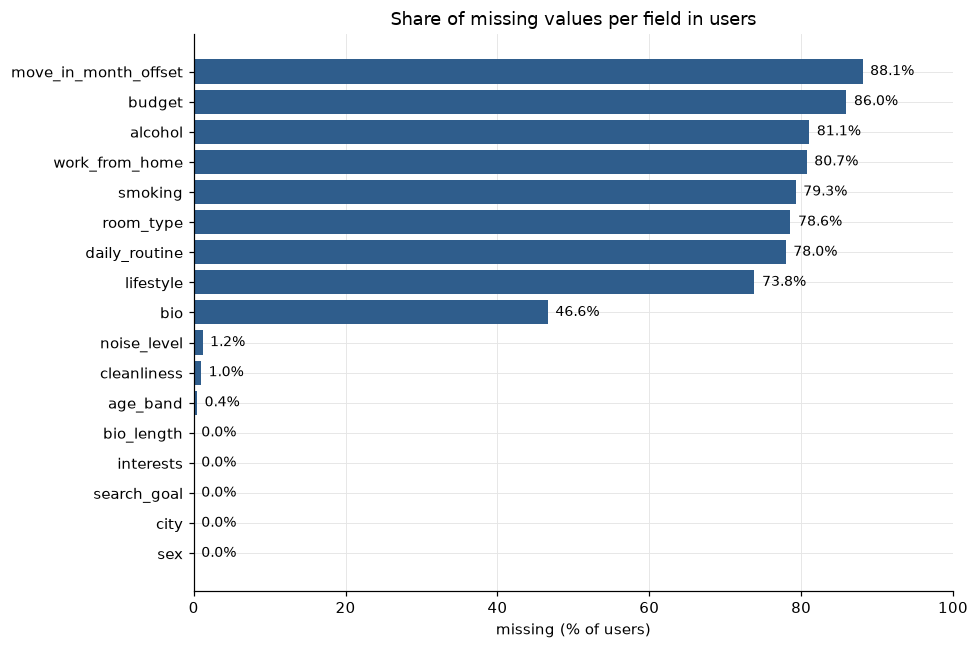

In [4]:
missing_pct = (users.isna().mean() * 100).drop("user_key").sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(missing_pct.index, missing_pct.values, color=PRIMARY)
for y, value in enumerate(missing_pct.values):
    ax.text(value + 1, y, f"{value:.1f}%", va="center", fontsize=9)
ax.set_xlim(0, 100)
ax.set_xlabel("missing (% of users)")
ax.set_title("Share of missing values per field in users")
plt.tight_layout()
plt.show()

## 4. Value sets of categorical fields

Counts include missing values (`NaN`). Codes are shown exactly as stored in the data.

In [5]:
CATEGORICAL = [
    "sex",
    "age_band",
    "city",
    "room_type",
    "search_goal",
    "daily_routine",
    "lifestyle",
    "work_from_home",
    "cleanliness",
    "noise_level",
    "smoking",
    "alcohol",
]

for col in CATEGORICAL:
    counts = users[col].value_counts(dropna=False)
    table = pd.DataFrame({"n": counts, "%": (counts / len(users) * 100).round(1)})
    print(f"\n### {col} ({len(counts)} values incl. NaN)")
    print(table.to_string())


### sex (3 values incl. NaN)
        n     %
sex            
F    1049  50.8
M     943  45.7
O      73   3.5

### age_band (7 values incl. NaN)
             n     %
age_band            
18-20     1116  54.0
21-23      431  20.9
24-26      224  10.8
27-30      126   6.1
36+         92   4.5
31-35       67   3.2
NaN          9   0.4

### city (10 values incl. NaN)
             n     %
city                
Wrocław    698  33.8
inne       578  28.0
Warszawa   310  15.0
Kraków     188   9.1
Poznań      99   4.8
Gdańsk      56   2.7
Łódź        45   2.2
Hyderabad   45   2.2
Lublin      26   1.3
Katowice    20   1.0

### room_type (3 values incl. NaN)
              n     %
room_type            
NaN        1623  78.6
SN          417  20.2
SH           25   1.2

### search_goal (2 values incl. NaN)
                n     %
search_goal            
LR           1902  92.1
HA            163   7.9

### daily_routine (4 values incl. NaN)
                  n     %
daily_routine            
NaN       

                   n     %
work_from_home            
NaN             1667  80.7
N                307  14.9
P                 56   2.7
Y                 35   1.7

### cleanliness (4 values incl. NaN)
                n     %
cleanliness            
FT           1083  52.4
VT            617  29.9
R             345  16.7
NaN            20   1.0

### noise_level (5 values incl. NaN)
                n     %
noise_level            
M            1028  49.8
Q             715  34.6
R             191   9.2
P             107   5.2
NaN            24   1.2

### smoking (5 values incl. NaN)
            n     %
smoking            
NaN      1637  79.3
N         291  14.1
V          89   4.3
O          45   2.2
Y           3   0.1

### alcohol (6 values incl. NaN)
            n     %
alcohol            
NaN      1674  81.1
BM        159   7.7
SO        106   5.1
ND         95   4.6
SN         24   1.2
NE          7   0.3


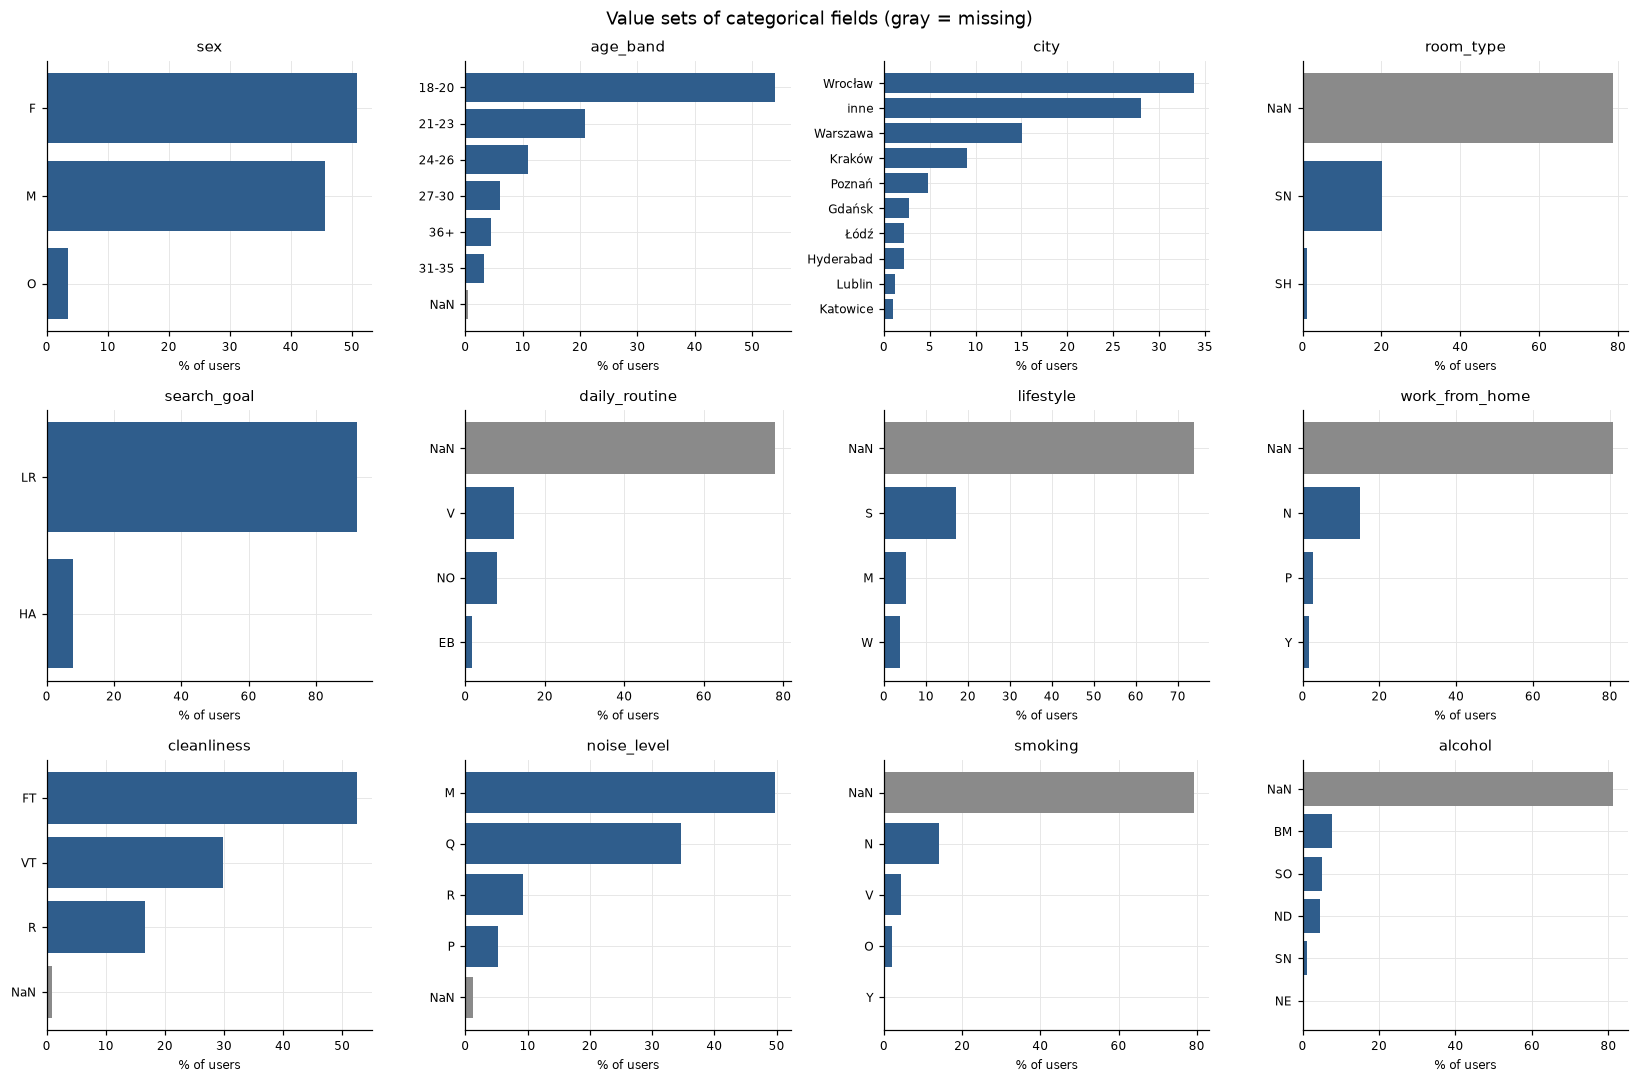

In [6]:
# Small multiples: one panel per field, one axis each. Missing values are shown in muted gray.
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
for ax, col in zip(axes.flat, CATEGORICAL, strict=False):
    counts = users[col].value_counts(dropna=False)
    labels = ["NaN" if pd.isna(v) else str(v) for v in counts.index]
    colors = [MUTED if pd.isna(v) else PRIMARY for v in counts.index]
    ax.barh(labels, counts.values / len(users) * 100, color=colors)
    ax.invert_yaxis()
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("% of users", fontsize=8)
    ax.tick_params(labelsize=8)
fig.suptitle("Value sets of categorical fields (gray = missing)", fontsize=12)
plt.tight_layout()
plt.show()

## 5. Numeric fields and anomalies

- `move_in_month_offset` has two negative values (-222, -338). They are probably entry errors, not
  real offsets. They are kept here and flagged; the analysis decision is pending.
- `budget` is present for only 290 users. Most values fall between 1000 and 3000. Seven values
  lie outside 500 to 5000 (2, 10, 8000, 10000, 15000, 30000, 30000). Likely outliers or entry
  errors, to check with the provider.
- `budget` is stored as `Decimal` (object dtype) and is converted to float only for the summary.

In [7]:
print("move_in_month_offset (value: n)")
print(users["move_in_month_offset"].value_counts(dropna=False).sort_index().to_string())

budget = pd.to_numeric(users["budget"])
print("\nbudget summary")
print(budget.describe().round(1).to_string())
print(
    "\nbudget values above 5000 or below 500:",
    sorted(budget[(budget > 5000) | (budget < 500)].dropna().tolist()),
)

move_in_month_offset (value: n)
move_in_month_offset
-338.0       1
-222.0       1
 0.0        13
 1.0        10
 2.0       153
 3.0        53
 4.0         8
 5.0         1
 6.0         3
 7.0         1
 8.0         1
 13.0        1
 NaN      1819

budget summary
count      290.0
mean      1975.9
std       2583.9
min          2.0
25%       1500.0
50%       1600.0
75%       2000.0
max      30000.0

budget values above 5000 or below 500: [2.0, 10.0, 8000.0, 10000.0, 15000.0, 30000.0, 30000.0]


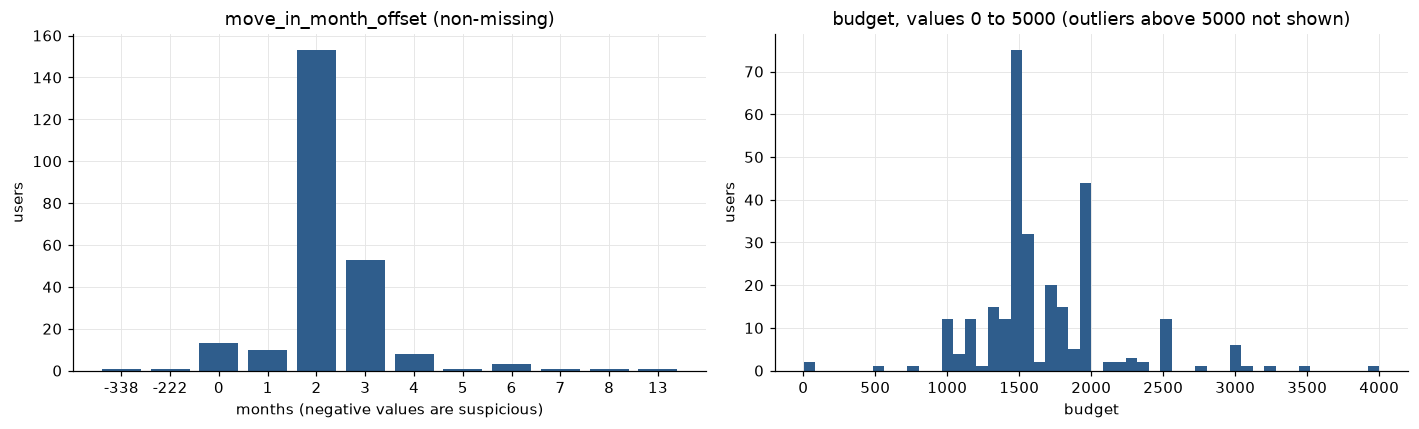

In [8]:
offsets = users["move_in_month_offset"].dropna().astype(int).value_counts().sort_index()
budget_in_range = budget[budget.between(0, 5000)].dropna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.bar(offsets.index.astype(str), offsets.values, color=PRIMARY)
ax1.set_title("move_in_month_offset (non-missing)")
ax1.set_xlabel("months (negative values are suspicious)")
ax1.set_ylabel("users")
ax2.hist(budget_in_range, bins=50, color=PRIMARY)
ax2.set_title("budget, values 0 to 5000 (outliers above 5000 not shown)")
ax2.set_xlabel("budget")
ax2.set_ylabel("users")
plt.tight_layout()
plt.show()

## 6. Interest tags (`interests`)

Each user has a JSON list of tags. The tag set has two styles that appear to describe the same
concepts:

- **snake_case keys**, for example `student`, `likes_calm`, `non_smoker`;
- **emoji plus label**, in Polish or English, for example `🎓 Student`, `🤫 Cisza po 22`.

Whether these pairs are the same tag has not been verified. Counts below are for the raw strings.

In [9]:
tag_lists = users["interests"].apply(json.loads)
tag_counts = pd.Series([tag for tags in tag_lists for tag in tags]).value_counts()
n_tags = tag_lists.str.len()

is_snake_case = tag_counts.index.str.fullmatch(r"[a-z_]+")
print(f"distinct raw tags: {len(tag_counts)}")
print(f"  snake_case: {is_snake_case.sum()}")
print(f"  emoji / label style: {(~is_snake_case).sum()}")
print(f"\ntags per user: min {n_tags.min()}, median {n_tags.median()}, max {n_tags.max()}")
print(f"users at the cap of 9 tags: {(n_tags == 9).sum()} of {len(users)}")
print(f"users with no tags: {(n_tags == 0).sum()}")

print("\nAll tags (raw string: number of users)")
print(tag_counts.to_string())

distinct raw tags: 124
  snake_case: 70
  emoji / label style: 54

tags per user: min 0, median 9.0, max 9
users at the cap of 9 tags: 1177 of 2065
users with no tags: 53

All tags (raw string: number of users)
student                           1143
non_smoker                         809
likes_calm                         636
extrovert                          598
night_owl                          569
values_privacy                     492
introvert                          470
cooking                            455
likes_pets                         452
movies_cinema                      436
gym                                433
loves_cleanliness                  376
travel                             354
gaming                             353
often_out                          352
always_headphones                  348
going_out_friends                  343
active_sport                       332
mostly_home                        322
likes_parties                      301
quiet_aft

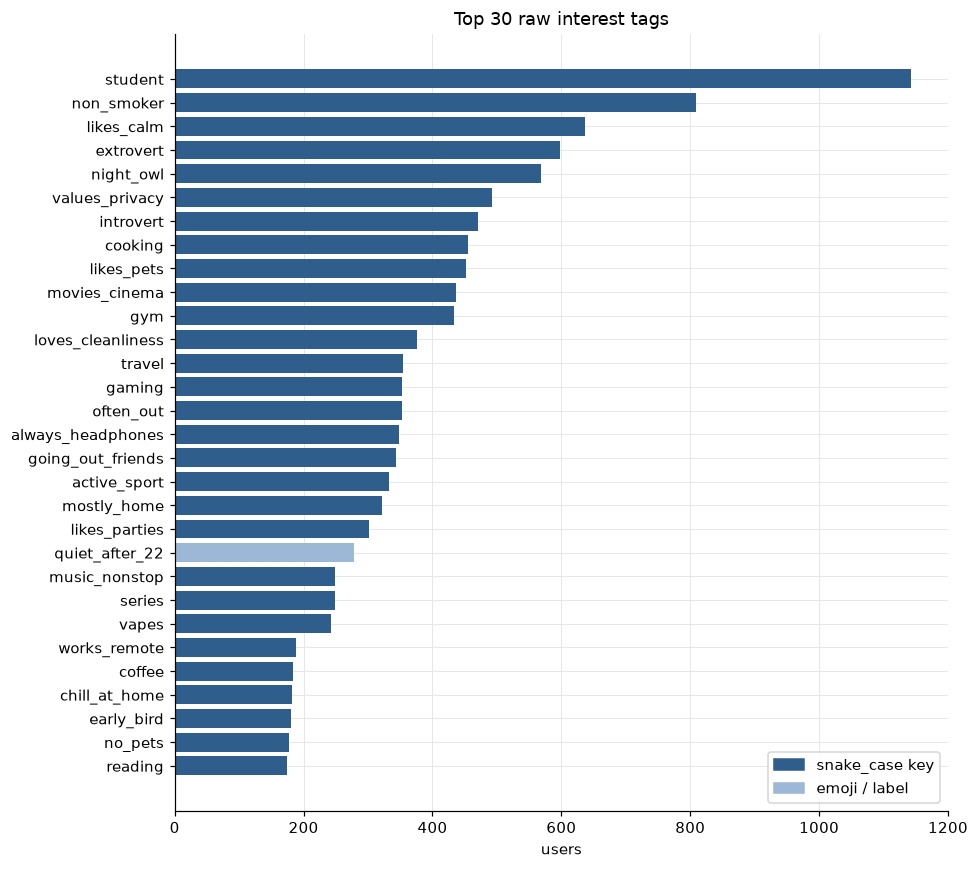

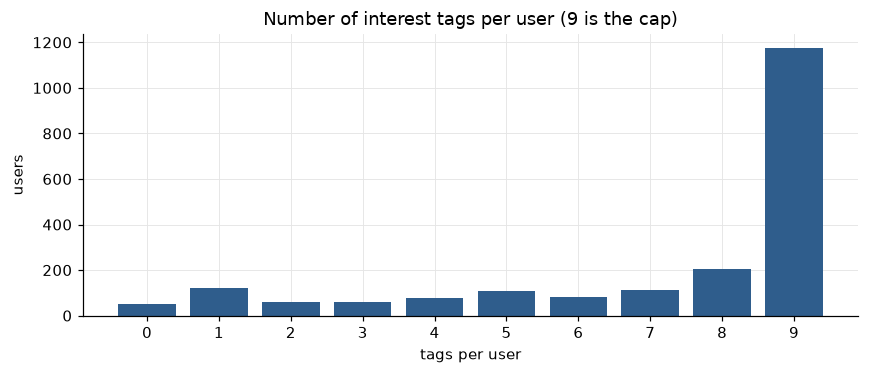

In [10]:
top = tag_counts.head(30)[::-1]
is_snake_case_top = top.index.str.fullmatch(r"[a-z_]+")
colors = [PRIMARY if snake else LIGHT for snake in is_snake_case_top]

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top.index, top.values, color=colors)
ax.set_xlabel("users")
ax.set_title("Top 30 raw interest tags")
ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=PRIMARY, label="snake_case key"),
        plt.Rectangle((0, 0), 1, 1, color=LIGHT, label="emoji / label"),
    ],
    loc="lower right",
)
plt.tight_layout()
plt.show()

tags_per_user = n_tags.value_counts().reindex(range(10), fill_value=0)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(tags_per_user.index.astype(str), tags_per_user.values, color=PRIMARY)
ax.set_xlabel("tags per user")
ax.set_ylabel("users")
ax.set_title("Number of interest tags per user (9 is the cap)")
plt.tight_layout()
plt.show()

## 7. Activity per user

Activity is counted from the action tables. A match counts once for each of its two users.

In [11]:
activity = pd.DataFrame(index=users["user_key"])
activity["profile_versions"] = profile_history.groupby("user_key").size()
activity["swipes_made"] = swipes.groupby("user_key").size()
activity["right_swipes_made"] = swipes[swipes["direction"] == "right"].groupby("user_key").size()
activity["matches"] = pd.concat([matches["user_a_key"], matches["user_b_key"]]).value_counts()
activity["chats"] = pd.concat([chats["user_a_key"], chats["user_b_key"]]).value_counts()
activity = activity.fillna(0).astype(int)

print(activity.describe().round(1).to_string())
print("\nusers with zero activity in each column:")
print((activity == 0).sum().to_string())

print("\nreferential check (keys in swipes/profile_history that are not in users):")
print("  swipes.user_key:", (~swipes["user_key"].isin(users["user_key"])).sum())
print("  profile_history.user_key:", (~profile_history["user_key"].isin(users["user_key"])).sum())

       profile_versions  swipes_made  right_swipes_made  matches   chats
count            2065.0       2065.0             2065.0   2065.0  2065.0
mean                2.2         56.4               11.1      0.7     2.7
std                 2.0         91.0               32.6      2.2    30.3
min                 0.0          0.0                0.0      0.0     0.0
25%                 1.0          5.0                0.0      0.0     1.0
50%                 1.0         21.0                1.0      0.0     1.0
75%                 3.0         66.0                8.0      0.0     2.0
max                30.0        705.0              395.0     36.0  1371.0

users with zero activity in each column:
profile_versions        9
swipes_made           291
right_swipes_made     903
matches              1598
chats                 470

referential check (keys in swipes/profile_history that are not in users):
  swipes.user_key: 0
  profile_history.user_key: 0


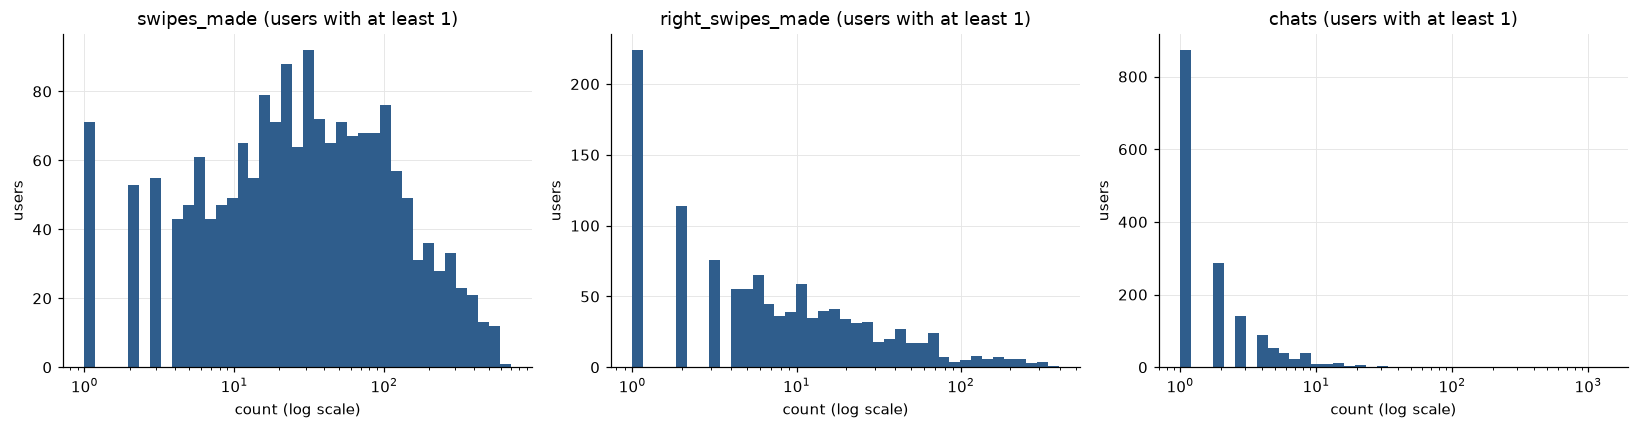

In [12]:
# Activity counts have a long tail, so use log-scaled bins; only users with at least one event.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["swipes_made", "right_swipes_made", "chats"], strict=False):
    values = activity.loc[activity[col] > 0, col]
    bins = np.logspace(0, np.log10(values.max()), 40)
    ax.hist(values, bins=bins, color=PRIMARY)
    ax.set_xscale("log")
    ax.set_title(f"{col} (users with at least 1)")
    ax.set_xlabel("count (log scale)")
    ax.set_ylabel("users")
plt.tight_layout()
plt.show()

## 8. Two random users

Sample with `random_state=42` for reproducibility. Bio text is replaced by a flag.

In [13]:
sample = users.sample(n=2, random_state=42)

view = sample.drop(columns=["bio"]).set_index("user_key")
view["interests"] = sample.set_index("user_key")["interests"].apply(
    lambda s: ", ".join(json.loads(s))
)
view["has_bio"] = (sample.set_index("user_key")["bio_length"] > 0).values
view = pd.concat([view, activity.loc[view.index]], axis=1)
view.T

user_key,0bfb9c68-9243-4f1f-86d3-a478852f3946,1e1770fa-548e-4b64-ae2d-7691d32d7c1b
sex,M,F
age_band,18-20,21-23
city,Gdańsk,inne
daily_routine,NaN,NaN
lifestyle,NaN,NaN
work_from_home,NaN,NaN
cleanliness,FT,FT
noise_level,M,Q
smoking,NaN,NaN
alcohol,NaN,NaN


## 9. Open points

- The lifestyle and room codes (`LR`, `HA`, `SN`, `SH`, `V`, `NO`, `FT`, ...) need a codebook from
  the provider before they are interpreted.
- The `Hyderabad` entries, the negative `move_in_month_offset` values and the extreme `budget`
  values need checking.
- The duplicate tag styles need a mapping before tag-based similarity (Jaccard) is computed.
- Bio content needs the personal-data audit before any text is displayed or analysed.